In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve
)

In [2]:
from pathlib import Path
# Project paths
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Configuration
TARGET = "is_fraud"
ID_COL = "id"

# Load data
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (699960, 26)
Test: (299984, 25)


In [3]:
X = train.drop(columns=[TARGET, ID_COL])
y = train[TARGET].astype(int)

# Identify feature types
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "str", "bool"]).columns.tolist()

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))
print("Fraud rate:", round(y.mean() * 100, 2), "%")

Numerical features: 13
Categorical features: 11
Fraud rate: 1.67 %


In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (559968, 24)
Validation: (139992, 24)


In [5]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

In [6]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

lr_probs = lr_model.predict_proba(X_val)[:, 1]

In [7]:
lgb_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

lgb_model = Pipeline([
    ("preprocessor", lgb_preprocessor),
    ("model", lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

lgb_model.fit(X_train, y_train)

lgb_probs = lgb_model.predict_proba(X_val)[:, 1]

In [10]:
def evaluate_model(name, y_true, probs, max_fpr=0.01):

    fpr, tpr, thresholds = roc_curve(y_true, probs)

    # Best recall under the FPR constraint
    valid = np.where(fpr <= max_fpr)[0]
    idx = valid[np.argmax(tpr[valid])]

    threshold = thresholds[idx]
    preds = (probs >= threshold).astype(int)

    return {
        "Model": name,
        "PR-AUC": average_precision_score(y_true, probs),
        "ROC-AUC": roc_auc_score(y_true, probs),
        "Recall@1%FPR": tpr[idx],
        "Precision": precision_score(y_true, preds, zero_division=0),
        "F1": f1_score(y_true, preds, zero_division=0),
        "Threshold": threshold
    }


results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_val, lr_probs),
    evaluate_model("LightGBM", y_val, lgb_probs)
])

display(results.round(4))

,Model,PR-AUC,ROC-AUC,Recall@1%FPR,Precision,F1,Threshold
0,Logistic Regression,0.4972,0.9404,0.5068,0.4638,0.4844,0.1787
1,LightGBM,0.5013,0.9440,0.5064,0.4627,0.4836,0.1886


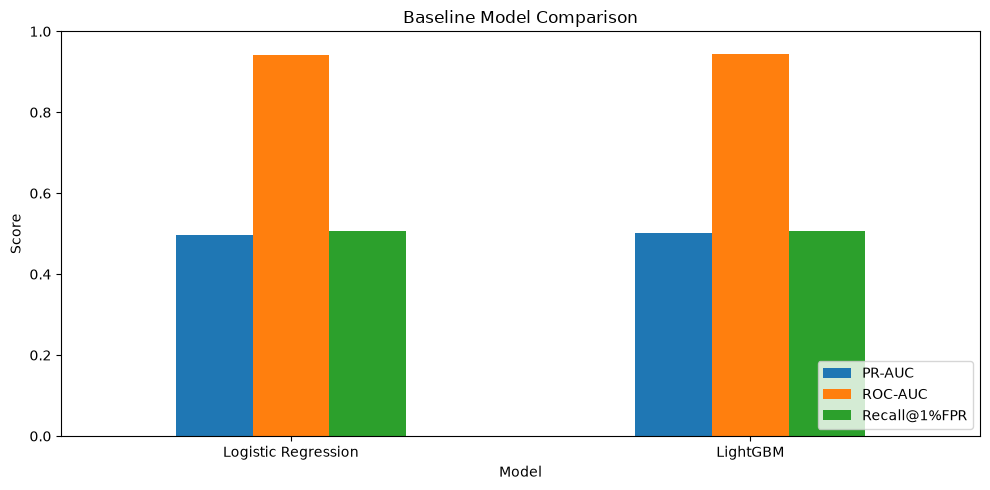

In [11]:
results.set_index("Model")[["PR-AUC", "ROC-AUC", "Recall@1%FPR"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)

plt.title("Baseline Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

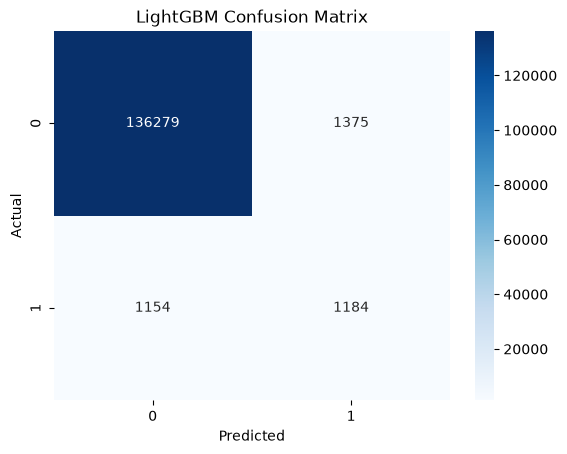

In [12]:
best_fpr, best_tpr, thresholds = roc_curve(y_val, lgb_probs)

idx = np.where(best_fpr <= 0.01)[0][np.argmax(best_tpr[best_fpr <= 0.01])]
threshold = thresholds[idx]

preds = (lgb_probs >= threshold).astype(int)

sns.heatmap(
    confusion_matrix(y_val, preds),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("LightGBM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
COST_FN = 200   # Cost of missing one fraudulent transaction (€)
COST_FP = 5     # Cost of incorrectly flagging a legitimate transaction (€)
def business_cost_curve(y_true, probabilities, cost_fn, cost_fp):

    thresholds = np.linspace(0.01, 0.99, 100)
    costs = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, predictions, labels=[0, 1]
        ).ravel()

        total_cost = (fn * cost_fn) + (fp * cost_fp)

        costs.append({
            "threshold": threshold,
            "false_positives": fp,
            "false_negatives": fn,
            "total_cost": total_cost
        })

    return pd.DataFrame(costs)

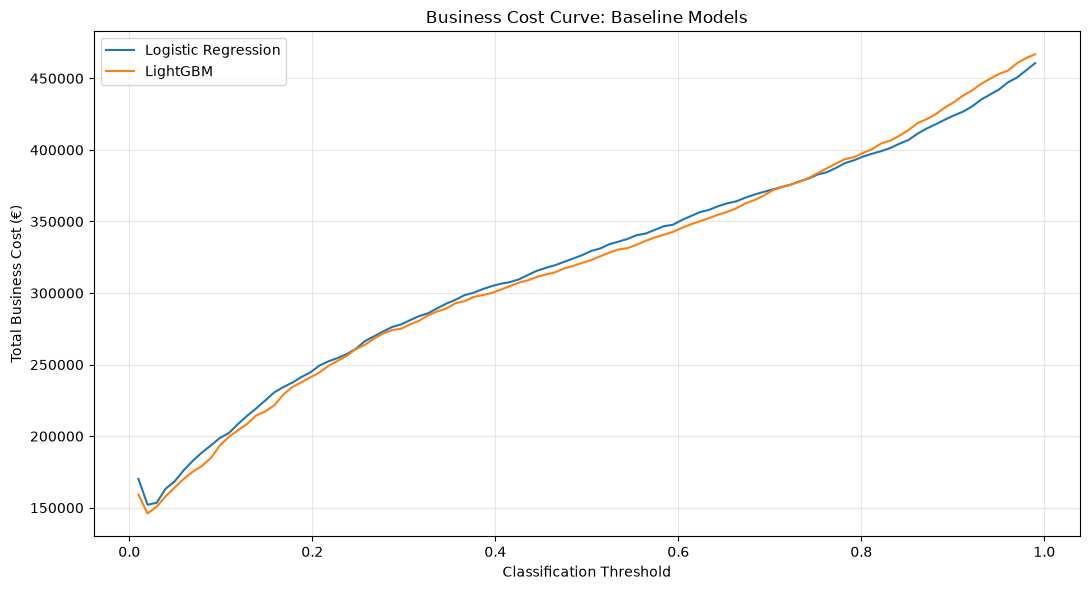

In [18]:
lr_cost = business_cost_curve(
    y_val, lr_probs, COST_FN, COST_FP
)

lgb_cost = business_cost_curve(
    y_val, lgb_probs, COST_FN, COST_FP
)
plt.figure(figsize=(11, 6))

plt.plot(
    lr_cost["threshold"],
    lr_cost["total_cost"],
    label="Logistic Regression"
)

plt.plot(
    lgb_cost["threshold"],
    lgb_cost["total_cost"],
    label="LightGBM"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Business Cost (€)")
plt.title("Business Cost Curve: Baseline Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Extract trained LightGBM model
lgb_pipeline = lgb_model.named_steps["model"]
feature_names = lgb_model.named_steps["preprocessor"].get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": lgb_pipeline.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(20))

,Feature,Importance
11,num__merchant_risk_score,1773
8,num__velocity_score,1566
0,num__amount_usd,1200
1,num__hours_since_last_txn,1200
5,num__customer_age,1183
3,num__distance_from_home_km,1076
6,num__account_balance_usd,1073
4,num__card_age_months,654
9,num__time_of_day_hour,603
2,num__txn_count_last_24h,391


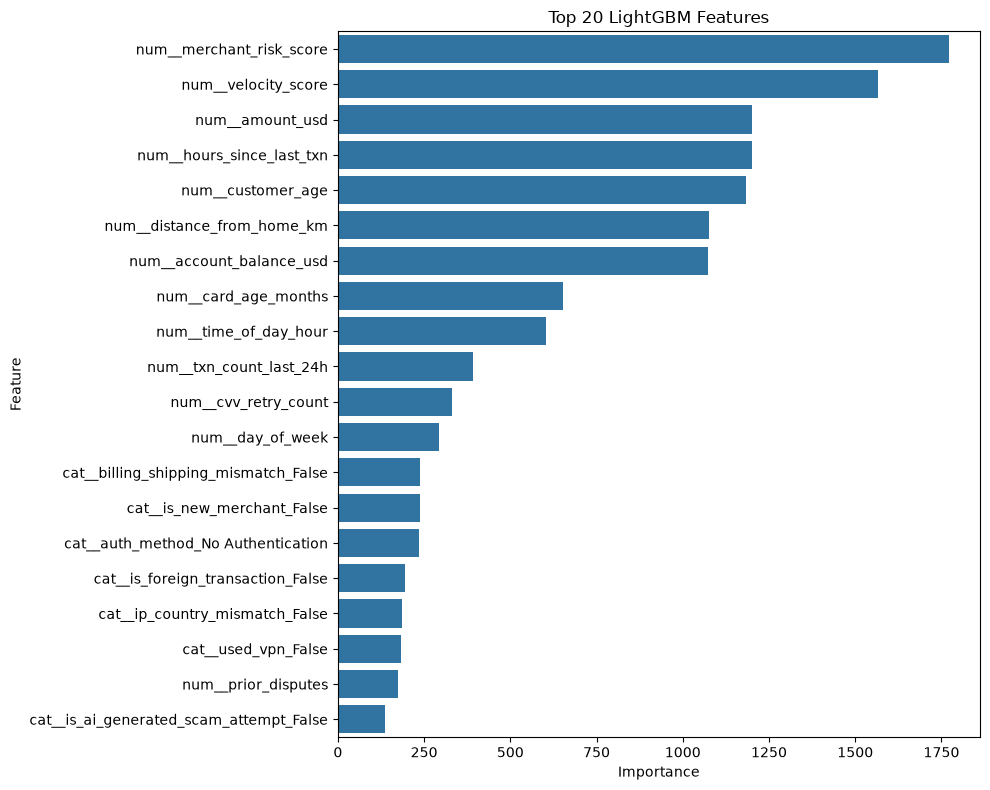

In [20]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 LightGBM Features")
plt.tight_layout()
plt.show()

In [22]:
lr_best = lr_cost.loc[lr_cost["total_cost"].idxmin()]
lgb_best = lgb_cost.loc[lgb_cost["total_cost"].idxmin()]

display(pd.DataFrame([
    {"Model": "Logistic Regression", **lr_best.to_dict()},
    {"Model": "LightGBM", **lgb_best.to_dict()}
]).set_index("Model"))

,threshold,false_positives,false_negatives,total_cost
Model,,,,
Logistic Regression,0.019899,14389.0,401.0,152145.0
LightGBM,0.019899,13154.0,401.0,145970.0


In [23]:
threshold = lgb_best["threshold"]
preds = (lgb_probs >= threshold).astype(int)

errors = X_val.copy()
errors["actual"] = y_val
errors["predicted"] = preds

false_negatives = errors[
    (errors["actual"] == 1) & (errors["predicted"] == 0)
]

false_positives = errors[
    (errors["actual"] == 0) & (errors["predicted"] == 1)
]

print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))

False negatives: 401
False positives: 13154


In [24]:
print("False negatives:")
display(false_negatives.describe().T)

print("False positives:")
display(false_positives.describe().T)

False negatives:


,count,mean,std,min,25%,50%,75%,max
amount_usd,401.0,104.372519,245.101066,2.65,16.11,28.26,47.98,2751.99
hours_since_last_txn,401.0,6.149800,6.497339,0.01,1.59,4.12,8.42,46.19
txn_count_last_24h,401.0,3.346633,1.346122,1.00,2.00,3.00,4.00,8.00
distance_from_home_km,401.0,13.880748,11.570353,0.04,4.43,10.50,21.31,50.89
card_age_months,401.0,46.603491,5.498171,31.00,43.00,46.00,50.00,63.00
customer_age,401.0,55.645885,16.486640,19.00,45.00,56.00,71.00,81.00
account_balance_usd,401.0,1984.837930,1756.351661,431.43,876.03,1428.00,2478.63,16892.10
cvv_retry_count,401.0,0.122195,0.350045,0.00,0.00,0.00,0.00,2.00
velocity_score,401.0,22.623192,9.778217,0.00,16.00,21.90,29.20,54.70
time_of_day_hour,401.0,12.039900,6.809068,0.00,6.00,12.00,18.00,23.00


False positives:


,count,mean,std,min,25%,50%,75%,max
amount_usd,13154.0,106.435258,228.145704,1.00,16.480,30.85,49.580,4455.69
hours_since_last_txn,13154.0,5.679000,5.963077,0.01,1.450,3.75,7.950,51.94
txn_count_last_24h,13154.0,3.575034,1.528821,0.00,2.000,3.00,5.000,11.00
distance_from_home_km,13154.0,13.632290,11.529737,0.01,4.565,10.35,19.870,57.05
card_age_months,13154.0,46.993614,5.584279,28.00,43.000,47.00,51.000,69.00
customer_age,13154.0,58.212255,15.701686,18.00,47.000,60.00,72.000,81.00
account_balance_usd,13154.0,2135.801243,3608.858601,119.69,826.155,1374.13,2585.315,88566.00
cvv_retry_count,13154.0,0.334271,0.498550,0.00,0.000,0.00,1.000,3.00
velocity_score,13154.0,25.950327,10.336547,0.00,18.600,25.25,33.100,65.00
time_of_day_hour,13154.0,11.649992,6.905916,0.00,6.000,12.00,18.000,23.00
